In [108]:
import os
from os.path import join
from pathlib import Path

import cv2
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, \
    confusion_matrix, precision_recall_curve
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
import sklearn

kagglehub.login()

# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

Path to competition files: /Users/vyankov/.cache/kagglehub/competitions/titanic


In [109]:
print('The scikit-learn version is {}.'.format(sklearn.__version__))

The scikit-learn version is 1.9.1.


In [110]:
random_state=42
max_depth=10 # default=None
threshold = 0.61
min_samples_split = 30 # default=2
min_samples_leaf = 20 # default=1

In [111]:
os.listdir(path)

['test.csv', 'train.csv', 'gender_submission.csv']

In [112]:
X_full = pd.read_csv(Path(join(path, 'train.csv')))
X_test = pd.read_csv(Path(join(path, 'test.csv')))

In [113]:
len(X_full)

891

In [114]:
X_full.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [115]:
def describe_columns(column_name: str, column_seq: pd.Series):
    print(f'Column: {column_name}')
    print(f'Type: {column_seq.dtype}')
    print(f"Has NANs: {column_seq.hasnans}")
    print(" ")

In [116]:
describe_columns('Survived', X_full.Survived)
describe_columns('Pclass', X_full.Pclass)
describe_columns('Sex', X_full.Sex)
describe_columns('Age', X_full.Age)
describe_columns('SibSp', X_full.SibSp)
describe_columns('Parch', X_full.Parch)
describe_columns('Ticket', X_full.Ticket)
describe_columns('Fare', X_full.Fare)
describe_columns('Cabin', X_full.Cabin)
describe_columns('Embarked', X_full.Embarked)


Column: Survived
Type: int64
Has NANs: False
 
Column: Pclass
Type: int64
Has NANs: False
 
Column: Sex
Type: object
Has NANs: False
 
Column: Age
Type: float64
Has NANs: True
 
Column: SibSp
Type: int64
Has NANs: False
 
Column: Parch
Type: int64
Has NANs: False
 
Column: Ticket
Type: object
Has NANs: False
 
Column: Fare
Type: float64
Has NANs: False
 
Column: Cabin
Type: object
Has NANs: True
 
Column: Embarked
Type: object
Has NANs: True
 


In [117]:
X_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [118]:
y = X_full.Survived
X = X_full.drop(['Survived', 'PassengerId', 'Name'], axis=1)
X_test = X_test.drop(['Name'], axis=1)

In [119]:
# drop columns with missing values for now
cols_with_missing = [col for col in X.columns if X[col].isnull().any()]
cols_with_missing

['Age', 'Cabin', 'Embarked']

In [120]:
X.drop(cols_with_missing, axis=1, inplace=True)
X_test.drop(cols_with_missing, axis=1, inplace=True)

In [121]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y,
                                                      train_size=0.8,
                                                      test_size=0.2,
                                                      random_state=0)

In [122]:
drop_X_train = X_train.select_dtypes(exclude=['object'])
drop_X_valid = X_valid.select_dtypes(exclude=['object'])
drop_X_test = X_test.select_dtypes(exclude=['object'])
print(drop_X_train.columns)
print(drop_X_valid.columns)
print(drop_X_test.columns)

Index(['Pclass', 'SibSp', 'Parch', 'Fare'], dtype='object')
Index(['Pclass', 'SibSp', 'Parch', 'Fare'], dtype='object')
Index(['PassengerId', 'Pclass', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [123]:
def build_pipeline(max_depth, random_state, min_samples_split, min_samples_leaf):
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=max_depth,
        random_state=random_state,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf
    )

    pipeline = Pipeline(steps=[
        ('model', model)
    ])

    return pipeline, model

def score_dataset(pipeline, X_train, X_valid, y_train, y_valid):
    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_valid)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    precision, recall, thresholds = precision_recall_curve(
        y_valid,
        probabilities
    )

    print("Accuracy:", accuracy_score(y_valid, predictions))

    print(classification_report(y_valid, predictions))
    print(confusion_matrix(y_valid, predictions))

    for p, r, t in zip(
        precision[:-1],
        recall[:-1],
        thresholds
    ):
        print(
            f"Threshold: {t:.2f}, "
            f"Precision: {p:.2f}, "
            f"Recall: {r:.2f}"
        )


In [124]:
param_grid = {
    "min_samples_split": [2, 5, 10, 20, 30, 50],
    "min_samples_leaf": [1, 2, 5, 10, 15, 20]
}

model_for_grid = DecisionTreeClassifier(
    criterion="gini",
    max_depth=max_depth,
    random_state=random_state,
    min_samples_split=min_samples_split,
    min_samples_leaf=min_samples_leaf
)

grid_search = GridSearchCV(
    estimator=model_for_grid,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(drop_X_train, y_train)

pipeline, model = build_pipeline(
    max_depth=max_depth,
    random_state=random_state,
    min_samples_split=min_samples_split,
    min_samples_leaf=min_samples_leaf
)
score_dataset(pipeline, drop_X_train, drop_X_valid, y_train, y_valid)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Accuracy: 0.7262569832402235
              precision    recall  f1-score   support

           0       0.73      0.89      0.80       110
           1       0.73      0.46      0.57        69

    accuracy                           0.73       179
   macro avg       0.73      0.68      0.68       179
weighted avg       0.73      0.73      0.71       179

[[98 12]
 [37 32]]
Threshold: 0.03, Precision: 0.39, Recall: 1.00
Threshold: 0.04, Precision: 0.40, Recall: 1.00
Threshold: 0.08, Precision: 0.42, Recall: 1.00
Threshold: 0.09, Precision: 0.43, Recall: 1.00
Threshold: 0.19, Precision: 0.46, Recall: 1.00
Threshold: 0.20, Precision: 0.46, Recall: 0.94
Threshold: 0.21, Precision: 0.48, Recall: 0.90
Threshold: 0.21, Precision: 0.48, Recall: 0.84
Threshold: 0.27, Precision: 0.48, Recall: 0.81
Threshold: 0.31, Precision: 0.53, Recall: 0.81
Threshold: 0.32, Precision: 0.52, Recall: 0.77
Threshold: 0.35, Precision: 0.53, Recall: 0.74

In [125]:
results = pd.DataFrame(grid_search.cv_results_)

results = results[
    [
        "param_min_samples_split",
        "param_min_samples_leaf",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

results = results.sort_values("rank_test_score")

print(results.to_string(index=False))

 param_min_samples_split  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
                      30                      20         0.571630        0.036686                1
                      20                      20         0.571630        0.036686                1
                      10                      20         0.571630        0.036686                1
                       5                      20         0.571630        0.036686                1
                       2                      20         0.571630        0.036686                1
                      50                      15         0.571118        0.048265                6
                       5                      15         0.564240        0.053976                7
                      10                      15         0.564240        0.053976                7
                      20                      15         0.564240        0.053976                7
          

In [126]:
best_model = grid_search.best_estimator_
# val_predictions = best_model.predict(drop_X_valid)
probabilities = best_model.predict_proba(drop_X_valid)[:, 1]
predictions = (probabilities >= threshold).astype(int)
print(classification_report(y_valid, predictions))

precision, recall, thresholds = precision_recall_curve(
        y_valid,
        probabilities
    )

for p, r, t in zip(
    precision[:-1],
    recall[:-1],
    thresholds
):
    print(
        f"Threshold: {t:.2f}, "
        f"Precision: {p:.2f}, "
        f"Recall: {r:.2f}"
    )

              precision    recall  f1-score   support

           0       0.73      0.89      0.80       110
           1       0.73      0.46      0.57        69

    accuracy                           0.73       179
   macro avg       0.73      0.68      0.68       179
weighted avg       0.73      0.73      0.71       179

Threshold: 0.03, Precision: 0.39, Recall: 1.00
Threshold: 0.04, Precision: 0.40, Recall: 1.00
Threshold: 0.08, Precision: 0.42, Recall: 1.00
Threshold: 0.09, Precision: 0.43, Recall: 1.00
Threshold: 0.19, Precision: 0.46, Recall: 1.00
Threshold: 0.20, Precision: 0.46, Recall: 0.94
Threshold: 0.21, Precision: 0.48, Recall: 0.90
Threshold: 0.21, Precision: 0.48, Recall: 0.84
Threshold: 0.27, Precision: 0.48, Recall: 0.81
Threshold: 0.31, Precision: 0.53, Recall: 0.81
Threshold: 0.32, Precision: 0.52, Recall: 0.77
Threshold: 0.35, Precision: 0.53, Recall: 0.74
Threshold: 0.40, Precision: 0.57, Recall: 0.71
Threshold: 0.40, Precision: 0.60, Recall: 0.67
Threshold: 0.45

In [127]:
ids = drop_X_test.PassengerId
probabilities = pipeline.predict_proba(drop_X_test.drop('PassengerId', axis=1))[:, 1]
preds_test = (probabilities >= threshold).astype(int)
output = pd.DataFrame({'PassengerId': ids,
                       'Survived': preds_test})
output.to_csv('submission.csv', index=False)

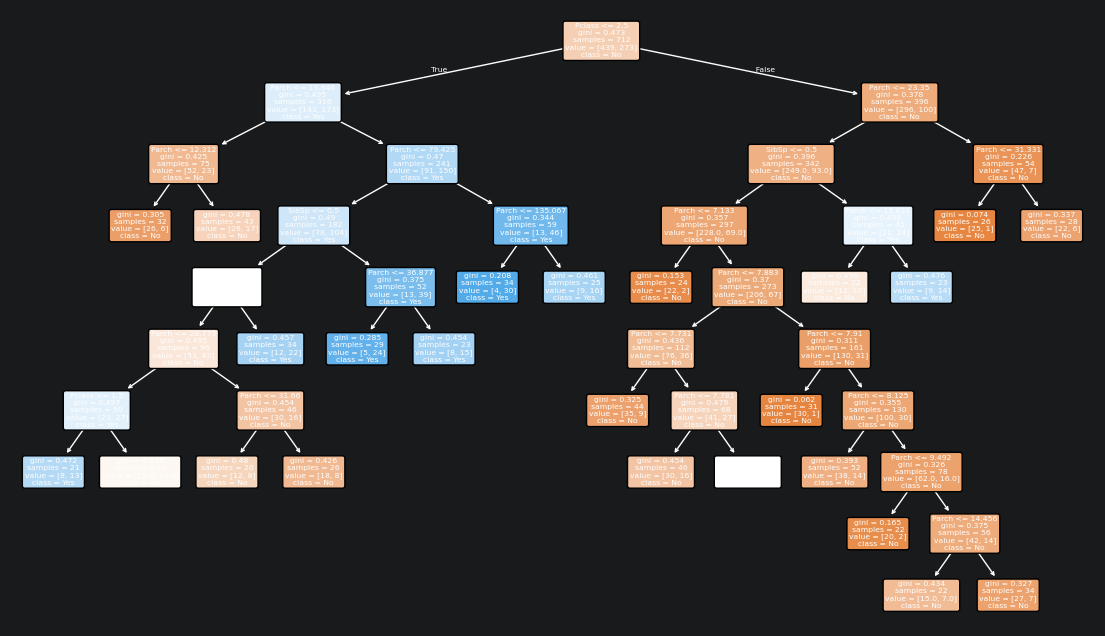

In [128]:
plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

plt.show()